In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv(r"C:\Users\Harsha BM\Downloads\archive\winequality-red.csv")
print("First five rows: ")
print(df.head)

First five rows: 
<bound method NDFrame.head of       fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0               7.4             0.700         0.00             1.9      0.076   
1               7.8             0.880         0.00             2.6      0.098   
2               7.8             0.760         0.04             2.3      0.092   
3              11.2             0.280         0.56             1.9      0.075   
4               7.4             0.700         0.00             1.9      0.076   
...             ...               ...          ...             ...        ...   
1594            6.2             0.600         0.08             2.0      0.090   
1595            5.9             0.550         0.10             2.2      0.062   
1596            6.3             0.510         0.13             2.3      0.076   
1597            5.9             0.645         0.12             2.0      0.075   
1598            6.0             0.310         0.47           

In [6]:
print("\nDataset shape: ")
print(df.shape)


Dataset shape: 
(1599, 12)


In [7]:
print("\nColumn names:")
print(df.columns)


Column names:
Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='str')


In [8]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [11]:
X = df.drop("quality", axis=1)
Y = df["quality"]

normalizer = MinMaxScaler()
X_normalized = normalizer.fit_transform(X)

print("\nNormalized data (first 5 rows):")
print(pd.DataFrame(X_normalized, columns=X.columns).head().round(3))


Normalized data (first 5 rows):
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0          0.248             0.397         0.00           0.068      0.107   
1          0.283             0.521         0.00           0.116      0.144   
2          0.283             0.438         0.04           0.096      0.134   
3          0.584             0.110         0.56           0.068      0.105   
4          0.248             0.397         0.00           0.068      0.107   

   free sulfur dioxide  total sulfur dioxide  density     pH  sulphates  \
0                0.141                 0.099    0.568  0.606      0.138   
1                0.338                 0.216    0.494  0.362      0.210   
2                0.197                 0.170    0.509  0.409      0.192   
3                0.225                 0.191    0.582  0.331      0.150   
4                0.141                 0.099    0.568  0.606      0.138   

   alcohol  
0    0.154  
1    0.215  
2    0.2

In [12]:
standardizer = StandardScaler()
X_standardized = standardizer.fit_transform(X)

print("\nStandardized data (first 5 rows):")
print(pd.DataFrame(X_standardized, columns=X.columns).head().round(3))


Standardized data (first 5 rows):
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0         -0.528             0.962       -1.391          -0.453     -0.244   
1         -0.299             1.967       -1.391           0.043      0.224   
2         -0.299             1.297       -1.186          -0.169      0.096   
3          1.655            -1.384        1.484          -0.453     -0.265   
4         -0.528             0.962       -1.391          -0.453     -0.244   

   free sulfur dioxide  total sulfur dioxide  density     pH  sulphates  \
0               -0.466                -0.379    0.558  1.289     -0.579   
1                0.873                 0.624    0.028 -0.720      0.129   
2               -0.084                 0.229    0.134 -0.331     -0.048   
3                0.108                 0.412    0.664 -0.979     -0.461   
4               -0.466                -0.379    0.558  1.289     -0.579   

   alcohol  
0   -0.960  
1   -0.585  
2   -0

In [15]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_standardized)

print("\nPCA output (first 5 rows):")
print(pd.DataFrame(X_pca, columns=["PC1", "PC2"]).head().round(3))


PCA output (first 5 rows):
     PC1    PC2
0 -1.620  0.451
1 -0.799  1.857
2 -0.748  0.882
3  2.358 -0.270
4 -1.620  0.451


In [16]:
print("\nOriginal number of features:", X.shape[1])
print("Reduced number of features:", X_pca.shape[1])

print("\nVariance retained by each component:")
print(pca.explained_variance_ratio_.round(4))

print("Total variance retained:", round(sum(pca.explained_variance_ratio_) * 100, 2), "%")


Original number of features: 11
Reduced number of features: 2

Variance retained by each component:
[0.2817 0.1751]
Total variance retained: 45.68 %


<function matplotlib.pyplot.show(close=None, block=None)>

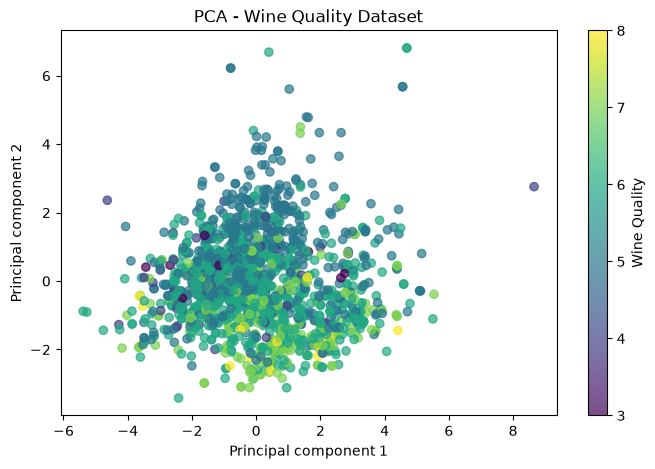

In [21]:
plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:,0], X_pca[:,1], c=Y, cmap="viridis", alpha=0.7)

plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title("PCA - Wine Quality Dataset")
plt.colorbar(label="Wine Quality")
plt.show